# 05 Policy simulation

**Stage 4.** Turn the results into a decision. Suppose we can contact only a fixed share of users. We compare three ways to choose them: by uplift score, by response score, and at random. For each, we read the extra outcomes caused by contacting them, per 100,000 users contacted, from the held out randomized data.

Contacting someone costs the same whether the contact works or not, so the model that finds more persuadable users per contact is the better policy. Intervals are 95 percent paired bootstrap intervals, and the final column is the gain over response targeting.

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent
RESULTS, REPORT = ROOT / "results", ROOT / "report"
RESULTS.mkdir(exist_ok=True); REPORT.mkdir(exist_ok=True)

from uplift.data import FEATURES, TREATMENT, OUTCOMES, make_splits, take, treated_share_ok, TRAIN_SIZES
from uplift import metrics as m

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
NAMES = {"response": "Response baseline", "s": "S-learner", "t": "T-learner", "x": "X-learner"}
COLORS = {"response": "#7a7a7a", "s": "#1c7293", "t": "#f2a93b", "x": "#0b3d5c"}
s5 = pd.read_parquet(RESULTS / "scores_5m.parquet")
t = s5[TREATMENT].to_numpy()
BUDGETS = (0.1, 0.2, 0.3)
POLICIES = {"response": "Response baseline", "s": "S-learner", "t": "T-learner", "x": "X-learner"}
rows = []
for outcome in OUTCOMES:
    y = s5[outcome].to_numpy()
    sc = {k: s5[f"{k}_{outcome}"].to_numpy() for k in POLICIES}
    for frac in BUDGETS:
        fn = lambda yy, tt, ss, f=frac: m.incremental_at(yy, tt, ss, f) * 100   # per 100,000 contacted
        boot = m.bootstrap_metrics(y, t, sc, metric=fn, n_boot=200)
        ci = m.bootstrap_ci(boot)
        for k in POLICIES:
            val = fn(y, t, sc[k])
            gain = m.paired_difference(boot, k, "response", val, fn(y, t, sc["response"])) if k != "response" else None
            rows.append(dict(outcome=outcome, budget=f"{int(frac*100)}%", policy=POLICIES[k], extra_per_100k=val, ci_lo=ci.loc[k, "lo"], ci_hi=ci.loc[k, "hi"],
                             gain_vs_response=None if gain is None else gain["diff"], gain_lo=None if gain is None else gain["lo"], gain_hi=None if gain is None else gain["hi"]))
        # random targeting reaches the average effect at any budget
        ate = (y[t == 1].mean() - y[t == 0].mean()) * 100_000
        rows.append(dict(outcome=outcome, budget=f"{int(frac*100)}%", policy="Random", extra_per_100k=ate))
policy = pd.DataFrame(rows)
policy.round(2).to_csv(RESULTS / "policy_simulation_5m.csv", index=False)
policy[policy.outcome == "visit"].round(1)

,outcome,budget,policy,extra_per_100k,ci_lo,ci_hi,gain_vs_response,gain_lo,gain_hi
0,visit,10%,Response baseline,5167.1,4622.8,5793.5,NaN,NaN,NaN
1,visit,10%,S-learner,6070.0,5610.7,6614.4,902.9,500.1,1349.7
2,visit,10%,T-learner,5862.0,5265.8,6390.1,694.9,283.3,1033.3
3,visit,10%,X-learner,6300.3,5726.9,6803.6,1133.2,728.3,1441.7
4,visit,10%,Random,995.2,NaN,NaN,NaN,NaN,NaN
5,visit,20%,Response baseline,3678.5,3414.9,4062.5,NaN,NaN,NaN
6,visit,20%,S-learner,3723.8,3484.1,4045.3,45.4,-70.1,169.8
7,visit,20%,T-learner,3860.0,3590.9,4173.3,181.6,-15.8,399.7
8,visit,20%,X-learner,3816.4,3566.8,4165.8,138.0,-70.3,318.0
9,visit,20%,Random,995.2,NaN,NaN,NaN,NaN,NaN


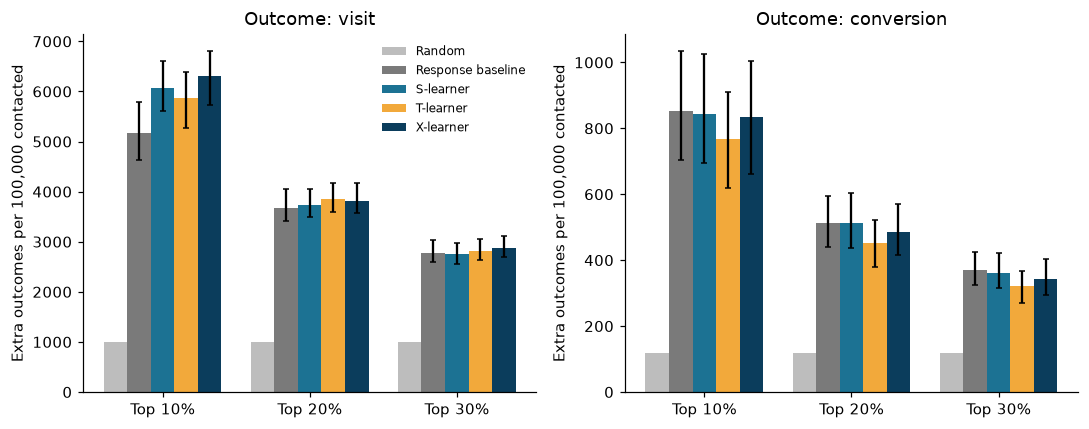

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
order = ["Random", "Response baseline", "S-learner", "T-learner", "X-learner"]
cols = {"Random": "#bdbdbd", "Response baseline": "#7a7a7a", "S-learner": "#1c7293", "T-learner": "#f2a93b", "X-learner": "#0b3d5c"}
for ax, outcome in zip(axes, OUTCOMES):
    p = policy[policy.outcome == outcome]
    w = 0.16
    for i, name in enumerate(order):
        q = p[p.policy == name].set_index("budget").reindex(["10%", "20%", "30%"])
        err = None if name == "Random" else [q.extra_per_100k - q.ci_lo, q.ci_hi - q.extra_per_100k]
        ax.bar(np.arange(3) + (i - 2) * w, q.extra_per_100k, w, yerr=err, color=cols[name], label=name, capsize=2)
    ax.set_xticks(range(3)); ax.set_xticklabels(["Top 10%", "Top 20%", "Top 30%"])
    ax.set_title(f"Outcome: {outcome}"); ax.set_ylabel("Extra outcomes per 100,000 contacted")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS / "policy_simulation_5m.png", dpi=200); fig.savefig(REPORT / "policy_simulation.png", dpi=200); plt.show()

## Reading the result

The table above gives, for each budget, how many extra outcomes each policy causes per 100,000 users contacted. The gain column is the difference to response targeting with its 95 percent interval. If that interval includes zero, the data does not show a reliable difference at that budget. We write the conclusion from these numbers once they are frozen.